# 02 · Centralized EoS baseline (plain GD)

**Why.** Every FedAvg claim is compared to plain GD. We need to see Edge of Stability on our own setup (tanh MLP 2×200, 5k CIFAR-10 subset, MSE, full batch) and pick usable step sizes.

**Setup.** One client, K = 1, η ∈ {0.02, 0.04, 0.08}, 10k steps, top Hessian eigenvalue every 10 steps.

**Units.** `sharpness·η/2`, so 1 = the classical edge 2/η.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)

In [2]:
runs = obs.load_runs("centralized"); traj = obs.load_traj("centralized")
runs[["run", "lr", "eq_sharpness", "eq_sharp_norm", "final_train_loss"]]

,run,lr,eq_sharpness,eq_sharp_norm,final_train_loss
0,M1_ainf_K1_lr0.02_slr1_s0,0.02,106.551,1.066,0.071
1,M1_ainf_K1_lr0.04_slr1_s0,0.04,54.389,1.088,0.034
2,M1_ainf_K1_lr0.08_slr1_s0,0.08,27.428,1.097,0.023


## 1. Sharpness over training

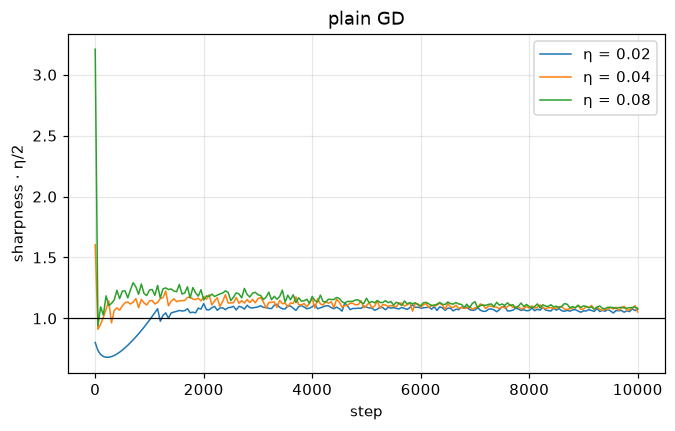

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr, g in traj.dropna(subset=["sharpness"]).groupby("lr"):
    ax.plot(g.steps, g.sharpness * lr / 2, lw=1, label=f"η = {lr:g}")
edge_line(ax); ax.set_xlabel("step"); ax.set_ylabel("sharpness · η/2"); ax.legend(); ax.set_title("plain GD")
plt.show()

## 2. Equilibrium and 1/η scaling

,lr,eq_sharpness,eq_sharp_norm,2/η,ratio to previous η
0,0.02,106.551,1.066,100.0,NaN
1,0.04,54.389,1.088,50.0,1.959
2,0.08,27.428,1.097,25.0,1.983


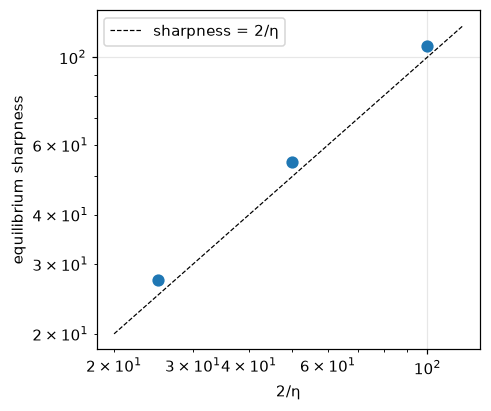

In [4]:
t = runs[["lr", "eq_sharpness", "eq_sharp_norm"]].sort_values("lr").copy()
t["2/η"] = 2 / t.lr
t["ratio to previous η"] = t.eq_sharpness.shift(1) / t.eq_sharpness
display(t.round(3))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.loglog(t["2/η"], t.eq_sharpness, "o", ms=7)
x = np.array([t["2/η"].min() * 0.8, t["2/η"].max() * 1.2]); ax.plot(x, x, "k--", lw=0.8, label="sharpness = 2/η")
ax.set_xlabel("2/η"); ax.set_ylabel("equilibrium sharpness"); ax.legend(); plt.show()

## 3. Where training starts relative to the edge

In [5]:
first = traj.dropna(subset=["sharpness"]).sort_values("steps").groupby("lr").first()
cross = traj.dropna(subset=["sharpness"]).assign(n=lambda d: d.sharpness * d.lr / 2)
cross = cross[cross.n >= 1].sort_values("steps").groupby("lr").steps.first()
pd.DataFrame({"initial sharpness": first.sharpness, "initial ·η/2": first.sharpness * first.index / 2,
              "first step at/above edge": cross}).round(3)

,initial sharpness,initial ·η/2,first step at/above edge
lr,,,
0.02,80.23,0.802,1050
0.04,80.23,1.605,0
0.08,80.23,3.209,0


## Conclusions

1. **EoS reproduced.** Sharpness settles near 2/η for every η and scales as 1/η (section 2).
2. **GD sits slightly above the edge (≈7–10%), not on it.** A small linear overshoot is tolerated and pulled back (self-stabilization). This number is the reference for the FedAvg notebooks.
3. **Only η = 0.02 shows progressive sharpening.** The network starts at sharpness ≈ 80, already past the edge for η = 0.04 and 0.08 (section 3). η = 0.08 was dropped from the FedAvg sweeps.